## fine tune on the few-shots


In [2]:
# Import necessary libraries
import os
import sys
# Add the utils folder to the system path so we can import custom modules
sys.path.append(os.path.abspath(os.path.join("../..")))
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

In [3]:
# Set random seed for reproducibility across runs
# This ensures that your results will be the same every time you run the notebook
seed_everything(40)  # for reproducibility

In [4]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",  # Path to training data
    train_ratio = 0.98,  # Use 98% for training, 2% for validation
    batchsize = 64,  # Number of samples per batch
    # columns_to_standardize = feature_names,  # Option to specify which columns to standardize
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],  # Remove these from features
    sequence_length = 20,  # Number of time steps in each sequence (t-19 to t0)
    threshold = True,  # Enable velocity thresholding
    threshold_value = 3.0,  # Only keep samples where vehicle speed > 3 m/s
    threshold_column = "vxCG",  # Column to apply threshold on (longitudinal velocity)
    target = "sideSlip",  # The variable we want to predict
    scaling = True,  # Apply standardization to features
    seed = 40,  # Random seed for train/val split
)

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

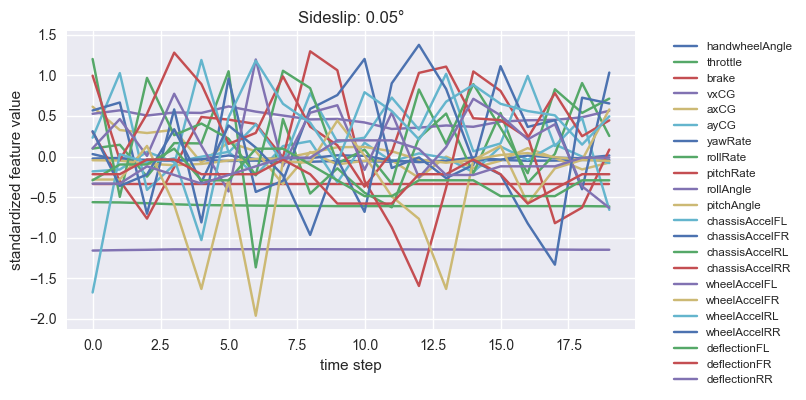

In [5]:
# Get one batch of data from the training dataloader
X, y = next(iter(train_dataloader))

# Visualize the first sample in the batch
plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)  # Plot all 22 features over 20 time steps
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")  # Show the target value
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [6]:
class RNN(nn.Module):
    """
    Recurrent Neural Network for sideslip angle prediction.
    
    Architecture:
    1. RNN Layer - Processes sequential input
    2. Fully Connected Layer - Transforms RNN output
    3. Output Layer - Produces final prediction
    
    Dropout layers are included to prevent overfitting.
    """
    def __init__(self, input_size, output_size=1, rnn_units=28, fc_units=28, 
                 activation_fct=nn.ReLU(), dropout=[0.0, 0, 0], rnn_nonlinearity='relu'):
        super(RNN, self).__init__()
        
        # RNN layer: processes the sequence and captures temporal dependencies
        self.rnn_layer = nn.RNN(input_size=input_size, hidden_size=rnn_units, 
                                num_layers=2, nonlinearity=rnn_nonlinearity, batch_first=True)
        
        # Fully connected layers for processing RNN output
        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)
        
        # Dropout layers to prevent overfitting (randomly zeros out neurons during training)
        self.dropout1 = nn.Dropout(dropout[0])  # Applied to input
        self.dropout2 = nn.Dropout(dropout[1])  # Applied after RNN
        self.dropout3 = nn.Dropout(dropout[2])  # Applied after FC layer
        
        self.activation_fct = activation_fct
 
    def forward(self, x):
        # x shape: (batch_size, sequence_length, input_size)
        x = self.dropout1(x)
        
        # Process sequence through RNN
        x, _ = self.rnn_layer(x)  # Output shape: (batch_size, sequence_length, rnn_units)
        
        # Take only the last time step's output (t0)
        x = x[:, -1, :]  # Shape: (batch_size, rnn_units)
        
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))  # Apply fully connected layer with activation
        x = self.dropout3(x)
        x = self.output_layer(x)  # Final prediction
        
        return x

In [7]:
# Set device for computation (CPU or GPU)
device = "cpu"  # Change to "cuda" if you have a GPU available

# Model hyperparameters
input_size = X.shape[2]  # Number of features (22 in this case)
rnn_units = 64  # Number of units in RNN hidden state
fc_units = 64  # Number of units in fully connected layer
output_size = 1  # Single output (sideslip angle)
lr = 0.0003  # Learning rate for optimizer

# Initialize the model with specified architecture
model = RNN(
    input_size=input_size, 
    output_size=output_size,
    rnn_units=rnn_units,
    fc_units=fc_units,
    dropout=[0.0, 0.0, 0.0]  # Dropout rates for [input, after_rnn, after_fc]
).to(device)

# Define loss function and optimizer
criterion = nn.L1Loss()  # Mean Absolute Error (MAE) - measures average prediction error
optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer for weight updates

In [8]:
# Training configuration
num_epochs =15  # Maximum number of training epochs
early_stop_thresh = 15  # Stop if no improvement for this many epochs
best_loss = np.inf  # Initialize with infinity
best_epoch = -1
best_model_state = None  # Will store the best model weights

# Lists to track training progress
train_curve = []
val_curve = []

for epoch in range(num_epochs):
    running_loss = 0
    
    # ========== TRAINING PHASE ==========
    model.train()  # Set model to training mode (enables dropout)
    for step, (x, y) in enumerate(train_dataloader):
        # Move data to device and reshape target
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer.zero_grad()  # Reset gradients from previous iteration
        pred = model(X)  # Forward pass: get predictions
        train_loss = criterion(pred, y)  # Calculate loss
        running_loss += train_loss.item()
        train_loss.backward()  # Backward pass: compute gradients
        optimizer.step()  # Update model weights
    
    avg_train_loss = running_loss / step
    train_curve.append(avg_train_loss)

    # ========== VALIDATION PHASE ==========
    model.eval()  # Set model to evaluation mode (disables dropout)
    running_val_loss = 0
    with torch.no_grad():  # Disable gradient computation (saves memory and computation)
        for val_step, (x, y) in enumerate(val_dataloader):
            X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
            val_loss = criterion(model(X_val), y_val)
            running_val_loss += val_loss.item()
    
    avg_val_loss = running_val_loss / val_step
    val_curve.append(avg_val_loss)
    
    # Print epoch summary
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f}", end="")
    
    # ========== EARLY STOPPING & MODEL CHECKPOINTING ==========
    if avg_val_loss < best_loss:
        # New best model found - save it!
        best_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': best_loss
        }, 'best_model.pth')
        print(f"  → New best validation loss: {best_loss:.5f}")
    elif epoch - best_epoch > early_stop_thresh:
        # No improvement for too long - stop training
        print(f"  → Early stopping triggered at epoch {epoch+1} (best epoch: {best_epoch+1})")
        break
    else:
        print("")

# ========== LOAD BEST MODEL ==========
if best_epoch != -1:
    checkpoint = torch.load('best_model.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n✓ Best model from epoch {best_epoch+1} loaded (Val Loss: {best_loss:.5f})")
else:
    print("\n⚠ No improvement found, using current model")
    
# ========= Extract FEW-SHOT samples for fine-tuning ========= #

FEW_MIN = -14.9
FEW_MAX =  11.6

def extract_few_shot(loader, low=FEW_MIN, high=FEW_MAX):
    X_few, y_few = [], []
    for X, y in loader:
        mask = ((y >= low) & (y <= high)).squeeze()
        if mask.any():
            X_few.append(X[mask])
            y_few.append(y[mask])

    X_few = torch.cat(X_few)
    y_few = torch.cat(y_few)

    print("Few-shot samples collected:", len(y_few))
    return X_few, y_few

X_few, y_few = extract_few_shot(train_dataloader)


Epoch 1/15 | Train Loss: 0.26240 | Val Loss: 0.19974  → New best validation loss: 0.19974
Epoch 2/15 | Train Loss: 0.18614 | Val Loss: 0.17451  → New best validation loss: 0.17451
Epoch 3/15 | Train Loss: 0.17199 | Val Loss: 0.17901
Epoch 4/15 | Train Loss: 0.16439 | Val Loss: 0.17409  → New best validation loss: 0.17409
Epoch 5/15 | Train Loss: 0.15895 | Val Loss: 0.15434  → New best validation loss: 0.15434
Epoch 6/15 | Train Loss: 0.15439 | Val Loss: 0.16743
Epoch 7/15 | Train Loss: 0.15044 | Val Loss: 0.14556  → New best validation loss: 0.14556
Epoch 8/15 | Train Loss: 0.14770 | Val Loss: 0.14918
Epoch 9/15 | Train Loss: 0.14370 | Val Loss: 0.13724  → New best validation loss: 0.13724
Epoch 10/15 | Train Loss: 0.14202 | Val Loss: 0.14971
Epoch 11/15 | Train Loss: 0.13918 | Val Loss: 0.14058
Epoch 12/15 | Train Loss: 0.13654 | Val Loss: 0.13435  → New best validation loss: 0.13435
Epoch 13/15 | Train Loss: 0.13513 | Val Loss: 0.13467
Epoch 14/15 | Train Loss: 0.13299 | Val Loss: 0.

In [9]:
X_fs = X_few
y_fs = y_few

few_dataset = torch.utils.data.TensorDataset(X_fs, y_fs)
few_loader = torch.utils.data.DataLoader(few_dataset, batch_size=64, shuffle=True)



In [10]:
# ========= FEW-SHOT FINE-TUNING ========= #

print("\nStarting few-shot fine-tuning...\n")

# Small LR to avoid destroying many-shot region
finetune_lr = 1e-4
optimizer_finetune = torch.optim.Adam(model.parameters(), lr=finetune_lr)

criterion = nn.L1Loss()
fine_epochs = 2   # 1–3 is ideal

for epoch in range(fine_epochs):
    model.train()
    total_loss = 0
    
    for Xb, yb in few_loader:
        Xb, yb = Xb.to(device), yb.to(device).reshape(len(yb), 1)

        optimizer_finetune.zero_grad()
        pred = model(Xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer_finetune.step()

        total_loss += loss.item()

    print(f"Fine-tune Epoch {epoch+1}/{fine_epochs} | Loss = {total_loss / len(few_loader):.6f}")

# Save final corrected model
torch.save(model.state_dict(), "model_finetuned_fewshot.pth")
print("\n✓ Few-shot fine-tuning complete! Saved as model_finetuned_fewshot.pth")



Starting few-shot fine-tuning...



Fine-tune Epoch 1/2 | Loss = 0.120386
Fine-tune Epoch 2/2 | Loss = 0.118400

✓ Few-shot fine-tuning complete! Saved as model_finetuned_fewshot.pth


In [11]:
# Load complete training data (unshuffled) for visualization
# This uses the same preprocessing pipeline to ensure consistency
train_dataloader_unshuffled = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=64,
    pipeline=pipeline,  # Use the same preprocessing as training
    load_anonymized_data=False  # We have ground truth for training data
)

../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [12]:
import plotly.graph_objects as go

# Set model to evaluation mode
model.eval()

# Storage for predictions and ground truth
total_loss = 0  
preds = []
ground_truths = []

# Generate predictions for all training data
with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        # Store predictions and ground truth
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Avg. Loss: {total_loss/step}")
    
    # Concatenate all batches into single arrays
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

Avg. Loss: 0.11652759551333802


In [13]:
print("\nLoading test data...")
test_dataloader = load_test_data(test_path = "../../datasets_challenge/test",
                                 batchsize = 64,
                                 pipeline = pipeline, 
                                 load_anonymized_data=True)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [14]:
# Generate predictions on test set
# Load fine-tuned model before test predictions
model.load_state_dict(torch.load("model_finetuned_fewshot.pth", map_location=device))
model.eval()
total_loss = 0  
test_preds = []
test_ground_truths = []  # Will contain placeholder values (all zeros)

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        # Note: loss is meaningless here since y contains placeholder values
        
        # Store predictions
        test_preds.append(pred.reshape(-1).cpu().numpy())
        test_ground_truths.append(y.reshape(-1).cpu().numpy())

    # Concatenate all batches
    test_ground_truths = np.concatenate(test_ground_truths)
    test_preds = np.concatenate(test_preds)
    
print("Shape of Predictions", test_preds.shape)

Shape of Predictions (49328,)


In [15]:
# Visualize test predictions (note: test_ground_truths are just zeros here)
fig = go.Figure()
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='placeholder (zeros)', 
                         line=dict(color='blue')))
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='predictions', 
                         line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Test Set: Placeholder vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

In [16]:
# Save predictions in the required format for submission
y_pred = pd.DataFrame({"predicted_sideslip": test_preds})
y_pred["id"] = range(len(test_preds))  # Add sample IDs (0 to 49327)

# Save to CSV file
y_pred.to_csv("predictions20.csv", index=False)

print(f"✓ Predictions saved to 'predictions20.csv'")
print(f"✓ Total samples: {len(test_preds)}")
print(f"✓ Ready for submission to the competition!")

✓ Predictions saved to 'predictions20.csv'
✓ Total samples: 49328
✓ Ready for submission to the competition!


In [17]:
dist_df = pd.read_csv("../../datasets_challenge/sideSlip_distribution.csv")

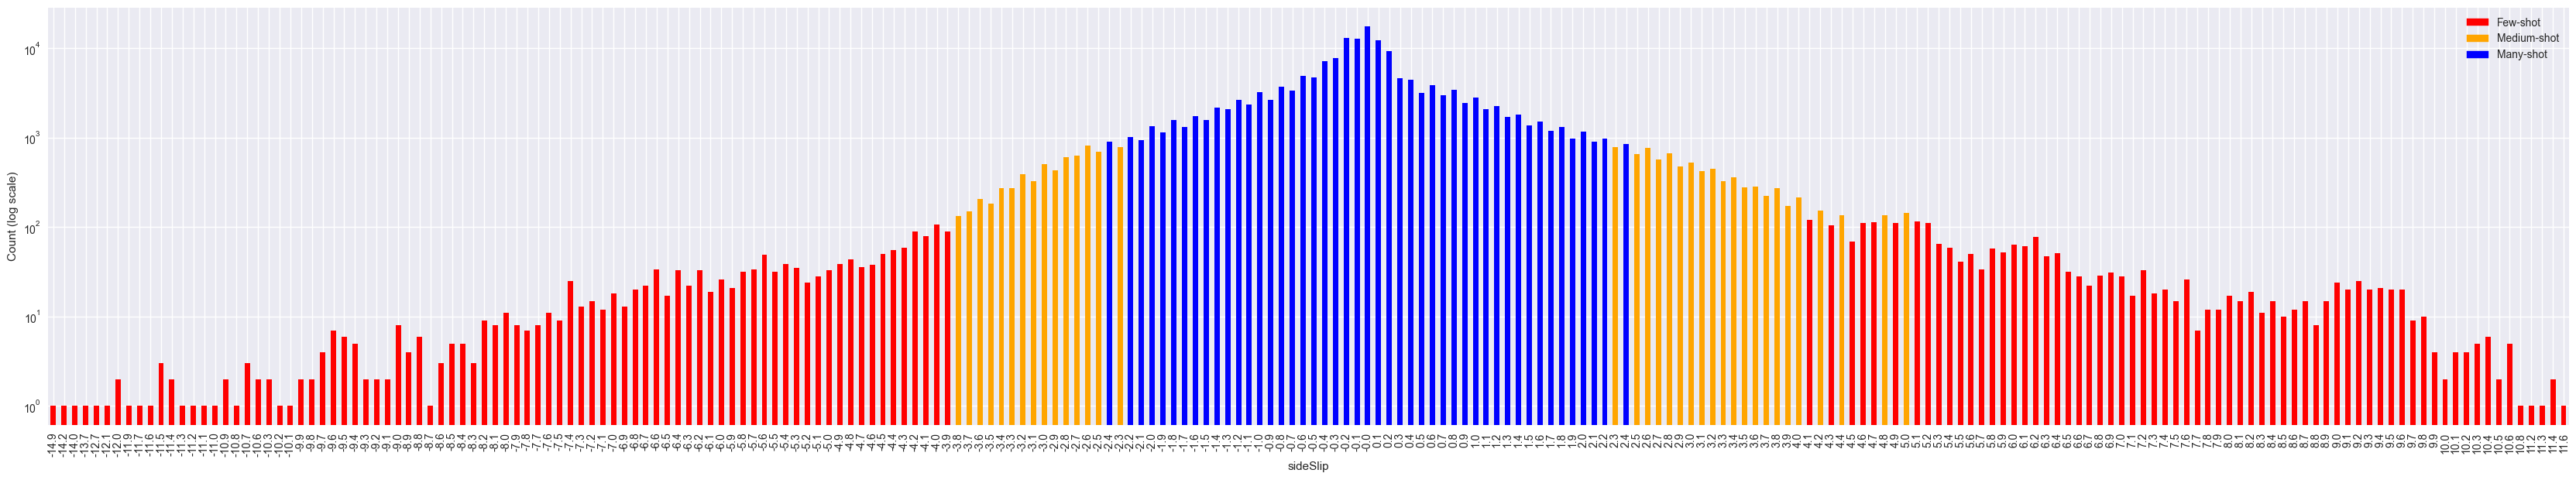

In [18]:
import matplotlib.patches as mpatches
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()
colors = shot_band_mapping.map({"few": "red", "medium": "orange", "many": "blue"})
ax = dist_df.plot(x='sideSlip', y='count', kind='bar', figsize=(42, 7), fontsize=10, color=colors)
few_patch = mpatches.Patch(color='red', label='Few-shot')
medium_patch = mpatches.Patch(color='orange', label='Medium-shot')
many_patch = mpatches.Patch(color='blue', label='Many-shot')
ax.legend(handles=[few_patch, medium_patch, many_patch], loc='upper right')
plt.yscale('log')
plt.ylabel('Count (log scale)')
plt.show()

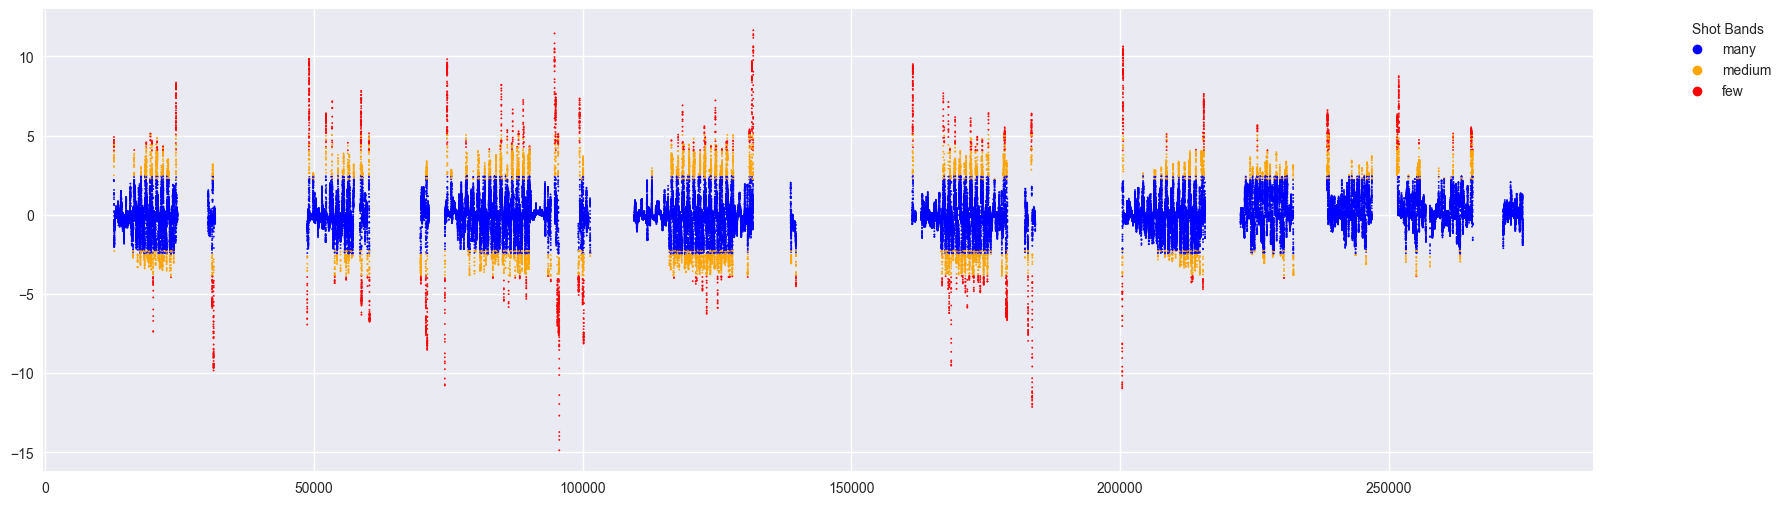

In [19]:
def concate_csv_dir(base_dir):
    all_dfs = []
    csv_lengths = {}
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file.endswith('.csv'):
                file_path = os.path.join(root, file)
                df = pd.read_csv(file_path)
                relative_path = os.path.relpath(file_path, base_dir)
                csv_lengths[relative_path] = len(df)
                all_dfs.append(df)
    
    return all_dfs, csv_lengths


df_list, csv_lengths = concate_csv_dir("../../datasets_challenge/train")
train_df = pd.concat(df_list, ignore_index=True)
train_df = train_df.where(train_df["vxCG"] > 3.0).dropna()  # Apply the same thresholding as during training


train_df["band"] = train_df["sideSlip"].round(1).map(shot_band_mapping)

plt.figure(figsize=(20, 6))
plt.scatter(train_df.index, train_df["sideSlip"], c=train_df["band"].map({"many": "blue", "medium": "orange", "few": "red"}), s=1)
# Plot the color code in a legend
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=7, label='many'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=7, label='medium'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='few')],
           title="Shot Bands", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [20]:
from utils.kaggle_metric import score

gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")


preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

score(gt_df, preds_df, row_id_column_name="id")

band
few       0.331334
many      0.107282
medium    0.178358
Name: L1, dtype: float64

In [21]:
import pandas as pd

# Load the distribution file
dist_df = pd.read_csv("../../datasets_challenge/sideSlip_distribution.csv")

# Few-shot bins (sideSlip values where band=="few")
few_bins = dist_df[dist_df["band"] == "few"]["sideSlip"].tolist()
few_bins = sorted([round(x, 3) for x in few_bins])

print("Few-shot bins:", few_bins[:20], "...")   # show first few
print("Total few-shot bins:", len(few_bins))

# Determine numeric min/max boundary of FEW-SHOT region
FEW_MIN = min(few_bins)
FEW_MAX = max(few_bins)

print("\nDetected FEW_MIN =", FEW_MIN)
print("Detected FEW_MAX =", FEW_MAX)


Few-shot bins: [-14.9, -14.2, -14.0, -13.7, -12.7, -12.1, -12.0, -11.9, -11.7, -11.6, -11.5, -11.4, -11.3, -11.2, -11.1, -11.0, -10.9, -10.8, -10.7, -10.6] ...
Total few-shot bins: 151

Detected FEW_MIN = -14.9
Detected FEW_MAX = 11.6
